In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
df_cleaned = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\datasets\teleco_dataset_formatted_2.csv")
df_cleaned.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TotalCharges_log
0,0,0,1,0,1,0,0,0,1,0,...,29.85,0,0,0,0,0,0,1,0,3.429137
1,1,0,0,0,34,1,0,1,0,1,...,1889.50,0,0,0,1,0,0,0,1,7.544597
2,1,0,0,0,2,1,0,1,1,0,...,108.15,1,0,0,0,0,0,0,1,4.692723
3,1,0,0,0,45,0,0,1,0,1,...,1840.75,0,0,0,1,0,0,0,0,7.518471
4,0,0,0,0,2,1,0,0,0,0,...,151.65,1,1,0,0,0,0,1,0,5.028148


Check for class imbalance : 

In [3]:
df_cleaned['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [4]:
df_cleaned.shape

(7043, 25)

In [5]:
print((df_cleaned["Churn"].sum()/7043) * 100, "%")

26.536987079369588 %


Class imbalance is not so severe to adjust the minority population size.

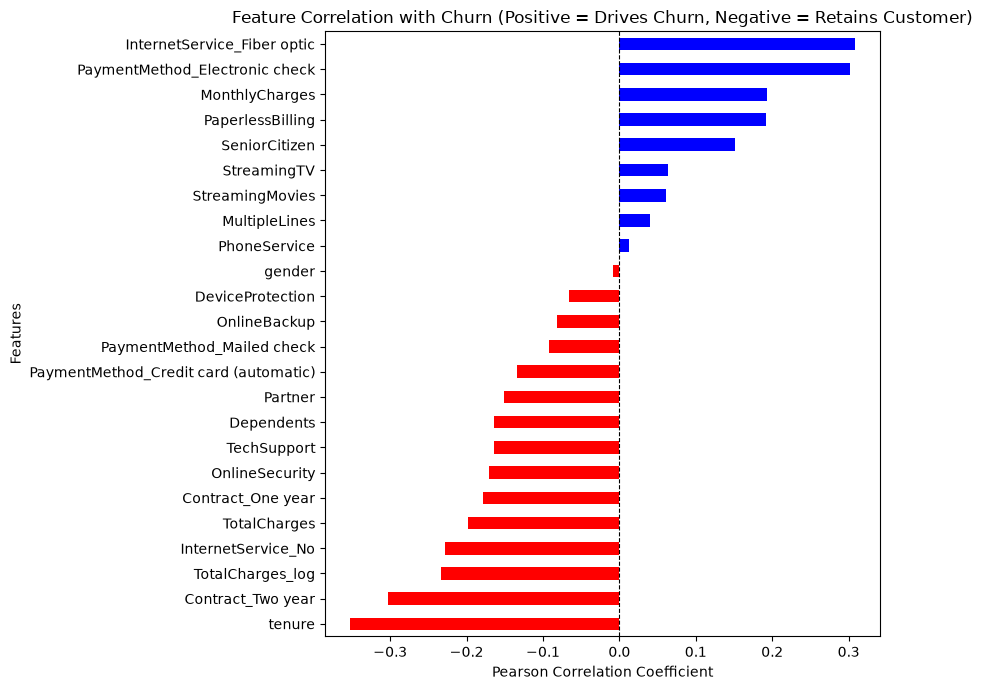

In [6]:
# EDA

import seaborn as sns


# Correlation of Churn column with every other column

churn_corr = df_cleaned.corr()["Churn"].drop('Churn').sort_values()

plt.figure(figsize=(9,7))
colors = ['blue' if  val > 0 else 'red' for val in churn_corr.values]
churn_corr.plot(kind='barh', color = colors)

plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Feature Correlation with Churn (Positive = Drives Churn, Negative = Retains Customer)')
plt.xlabel('Pearson Correlation Coefficient')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

C:\Users\dhanu\AppData\Local\Temp\ipykernel_8776\2738454412.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df_cleaned, x = 'Churn', y = 'TotalCharges_log', palette = 'Set1', ax = axes[2])
C:\Users\dhanu\AppData\Local\Temp\ipykernel_8776\2738454412.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(['No Churn (0)', 'Churn (1)'])


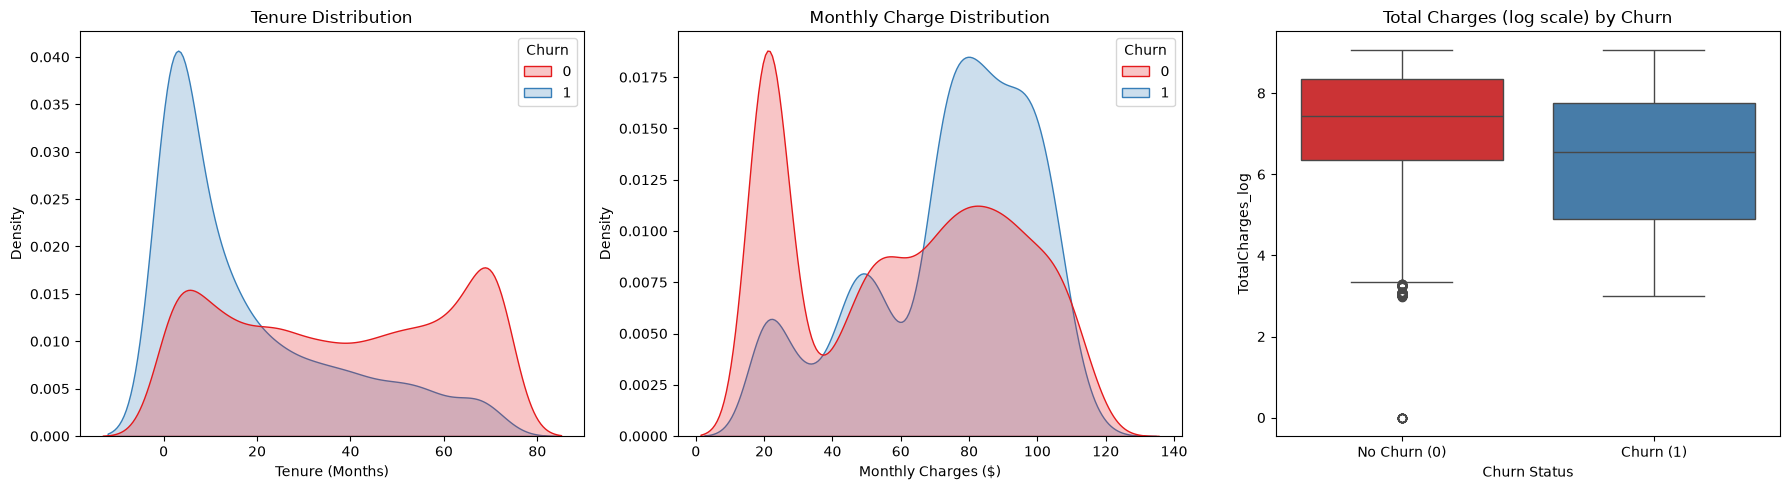

In [7]:
# Checking the effect of numerical columns on Churn

fig, axes = plt.subplots(1, 3, figsize = (18,5))

# Tenure period vs Churn
sns.kdeplot(data = df_cleaned, x = 'tenure', hue = 'Churn', common_norm = False, fill = True, palette = 'Set1', ax = axes[0])
axes[0].set_title("Tenure Distribution")
axes[0].set_xlabel("Tenure (Months)")

# Monthly Charge vs Churn
sns.kdeplot(data = df_cleaned, x = 'MonthlyCharges', hue = 'Churn', common_norm = False, fill = True, palette = 'Set1', ax = axes[1])
axes[1].set_title("Monthly Charge Distribution")
axes[1].set_xlabel("Monthly Charges ($)")

# Total Charges (log scale) vs Churn
sns.boxplot(data = df_cleaned, x = 'Churn', y = 'TotalCharges_log', palette = 'Set1', ax = axes[2])
axes[2].set_title("Total Charges (log scale) by Churn")
axes[2].set_xticklabels(['No Churn (0)', 'Churn (1)'])
axes[2].set_xlabel("Churn Status")

plt.tight_layout()
plt.show()

### Inference : 
- In the tenure vs churn density plot, we can observe that there are many customers who churned in the initial stages of the service and the amount of people that churn decreased at longer tenure periods. People who didn't churn, stood fixed until their complete tenure period is finished.

- In the Monthly Charge Distribution plot, we can observe high number of customers that churned where the monthly charges were significantly higher, similarly, high number of customers who didn't churn, were in the lower monthly charges region.

- In the box plot comparing the number of people who churned or not against the total charges, we can observe that a significant majority didn't churn even if the total charges were slightly higher, than those people who churned even if the total charges were on the lower side.

C:\Users\dhanu\AppData\Local\Temp\ipykernel_8776\3656822476.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = churn_rates.index, y = churn_rates.values, palette='magma', ax = axes[i])
C:\Users\dhanu\AppData\Local\Temp\ipykernel_8776\3656822476.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = churn_rates.index, y = churn_rates.values, palette='magma', ax = axes[i])
C:\Users\dhanu\AppData\Local\Temp\ipykernel_8776\3656822476.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = churn_rates.index, y = churn_rates.values, palette=

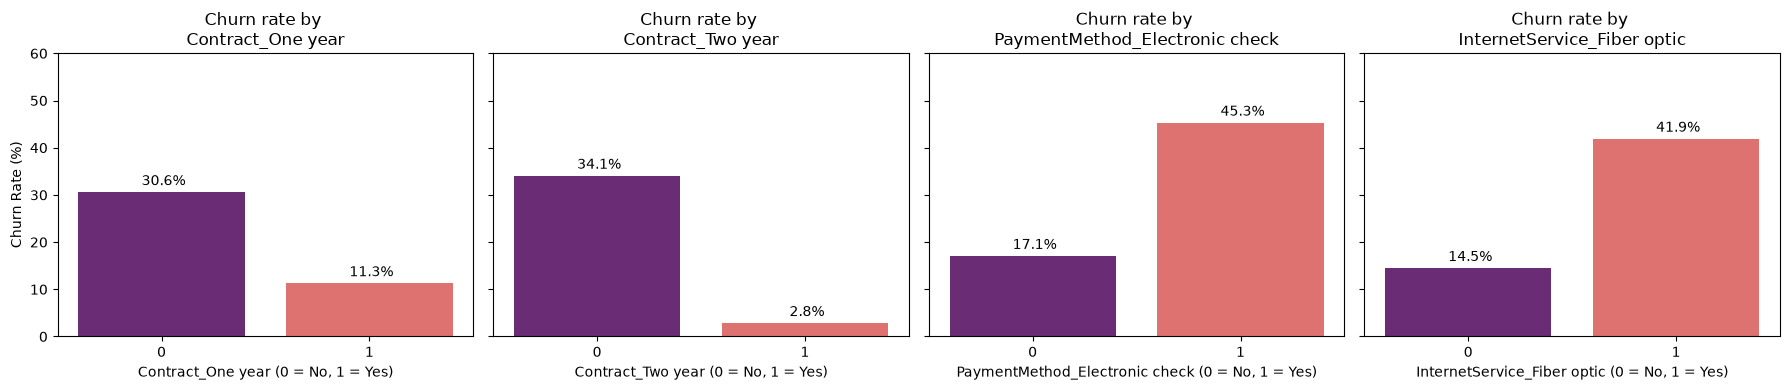

In [10]:
# Churn Rate vs Internet Service, Payment Method, and Contract time

important_segments = ['Contract_One year', 'Contract_Two year', 'PaymentMethod_Electronic check', 'InternetService_Fiber optic']

fig, axes = plt.subplots(1, 4, figsize = (18, 4), sharey = True)

for i, col in enumerate(important_segments):
    churn_rates = df_cleaned.groupby(col)["Churn"].mean() * 100 
    sns.barplot(x = churn_rates.index, y = churn_rates.values, palette='magma', ax = axes[i])

    axes[i].set_title(f'Churn rate by \n{col}')
    axes[i].set_xlabel(f"{col} (0 = No, 1 = Yes)")
    axes[i].set_ylabel("Churn Rate (%)" if i == 0 else '')
    axes[i].set_ylim(0, 60)

    for p in axes[i].patches :
        axes[i].annotate(f"{p.get_height() : .1f}%",
                         (p.get_x() + p.get_width() / 2., p.get_height() + 1.5), ha = 'center', fontsize = 10)

plt.tight_layout()
plt.show()

### Inference :
- Customers who have taken a contract for one or two years have less churn rate, compared to those customers without any contract, exhibiting a larger churn rate.

- Presence of payment method in electronic check show slight correlation towards churning, since those customers without this payment method are churning less.

- Similarly, Presence of Internet Service via Fiber Optic is showing higher Churn Rate compared to lack of this service for customers. 

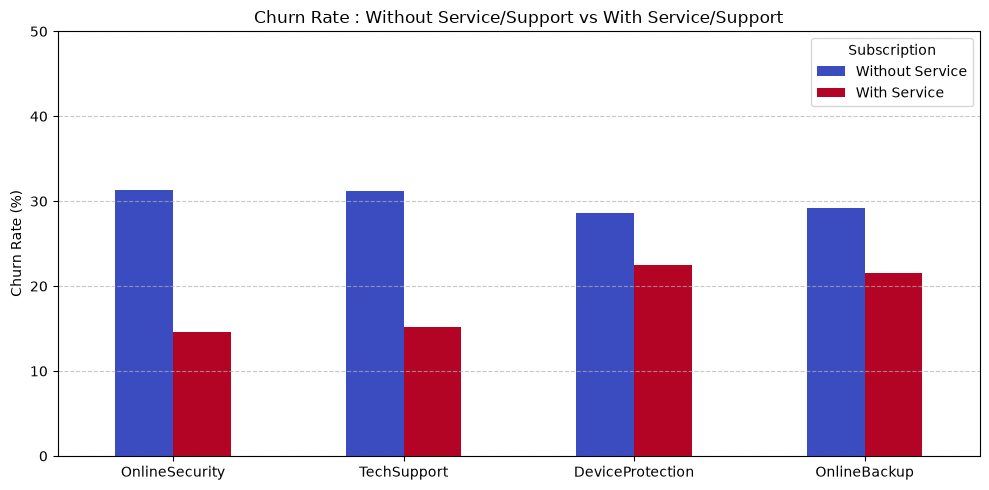

In [11]:
# Security and Support vs Churn rates

support_based_cols = ["OnlineSecurity", "TechSupport", "DeviceProtection", "OnlineBackup"]

rates_support = {col : [df_cleaned[df_cleaned[col] == 0]['Churn'].mean() * 100, 
                        df_cleaned[df_cleaned[col] == 1]['Churn'].mean() * 100] 
                for col in support_based_cols}


df_support_data = pd.DataFrame(rates_support, index = ['Without Service', 'With Service']).T

df_support_data.plot(kind = 'bar', figsize = (10, 5), colormap = 'coolwarm')

plt.title("Churn Rate : Without Service/Support vs With Service/Support")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation = 0)
plt.ylim(0, 50)
plt.legend(title = 'Subscription')
plt.grid(axis = 'y', linestyle = '--', alpha = 0.7)

plt.tight_layout()
plt.show()

### Inference : 
- There is a trend observed, Churn rates are higher on the side where no service or support was provided to the customers, and lower churn rates comparatively where support or some kind of additional service was provided to customers.
